# 05 · Clasificación P2: atrasado, a tiempo o adelantado
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Clasificar el estado final de la vuelta en el punto 18 con las mismas observaciones y variables de P1: atrasado (≥ 5 min), adelantado (≥ 3 min de adelanto) o a tiempo. Se comparan clasificadores directos con dos referencias (clase mayoritaria y persistencia de la clase del último atraso observado) y con el mejor regresor de P1 discretizado con los mismos umbrales. Se analiza la sensibilidad a los umbrales usando terciles del entrenamiento.

**Entradas:** `data/processed/corte_k{k}.pkl`, `data/processed/04_pred_test.pkl`, `results/tables/04_mejor_modelo_por_k.csv`. **Salidas:** `results/tables/05_*.csv`, `results/figures/05_*.png`.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.variables import CORTES, columnas_modelo
from src.particion import pliegues
from src.modelos import CLASIFICADORES, pipeline, rejilla
from src.evaluacion import metricas_clasificacion
from src import graficos

SEMILLA = 42
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
UMBRAL_ATRASO, UMBRAL_ADELANTO = 5, 3
CLASES = ["adelantado", "a tiempo", "atrasado"]
warnings.filterwarnings("ignore", category=ConvergenceWarning)
graficos.estilo()


def puntaje_atrasado(modelo, X):
    """Probabilidad de 'atrasado' o, si el modelo no la da (SVM), su puntaje de decisión."""
    i = list(modelo.classes_).index("atrasado")
    if hasattr(modelo, "predict_proba"):
        try:
            return modelo.predict_proba(X)[:, i]
        except AttributeError:
            pass
    return modelo.decision_function(X)[:, i]


def a_clase(valores, atraso=UMBRAL_ATRASO, adelanto=UMBRAL_ADELANTO):
    v = np.asarray(valores, float)
    return np.where(v >= atraso, "atrasado", np.where(v <= -adelanto, "adelantado", "a tiempo"))

## 1. Distribución de clases

In [2]:
x9 = pd.read_pickle(DIR_PROC / "corte_k9.pkl")
dist = pd.crosstab(a_clase(x9["y"]), x9["conjunto"], normalize="columns").mul(100).round(1).loc[CLASES]
dist.to_csv(DIR_TAB / "05_distribucion_clases.csv")
dist

conjunto,test,train
row_0,,
adelantado,11.8,12.0
a tiempo,60.5,54.1
atrasado,27.7,33.9


## 2. Clasificadores con búsqueda en rejilla (F1 macro en validación)

In [3]:
mejores = pd.read_csv(DIR_TAB / "04_mejor_modelo_por_k.csv").set_index("k")["modelo"]
pred_reg = pd.read_pickle(DIR_PROC / "04_pred_test.pkl")
hiper, filas, matrices = [], [], {}
inicio = time.time()
for k in CORTES:
    x = pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl")
    tr, te = x[x["conjunto"] == "train"].reset_index(drop=True), x[x["conjunto"] == "test"].reset_index(drop=True)
    y_tr, y_te = a_clase(tr["y"]), a_clase(te["y"])
    cols = columnas_modelo(x)
    cv = pliegues(tr["bloque"])

    filas.append({"k": k, "modelo": "Clase mayoritaria", **metricas_clasificacion(y_te, np.full(len(te), "a tiempo"))})
    filas.append({"k": k, "modelo": "Persistencia de clase",
                  **metricas_clasificacion(y_te, a_clase(te["atr_ultimo"].fillna(0)), te["atr_ultimo"].fillna(0))})
    pr = pred_reg[(pred_reg["k"] == k) & (pred_reg["modelo"] == mejores[k])].set_index("id").loc[te["id"], "pred"]
    filas.append({"k": k, "modelo": f"P1 discretizado ({mejores[k]})",
                  **metricas_clasificacion(y_te, a_clase(pr), pr.to_numpy())})

    for nombre, (modelo, grid) in CLASIFICADORES.items():
        busqueda = GridSearchCV(pipeline(cols, clone(modelo)), rejilla(grid), cv=cv, scoring="f1_macro", n_jobs=-1)
        busqueda.fit(tr[cols], y_tr)
        p = busqueda.predict(te[cols])
        prob = puntaje_atrasado(busqueda, te[cols])
        params = {q.replace("modelo__", ""): v for q, v in busqueda.best_params_.items()}
        hiper.append({"k": k, "modelo": nombre, "mejores_parametros": json.dumps(params, ensure_ascii=False),
                      "F1_macro_val": busqueda.best_score_})
        filas.append({"k": k, "modelo": nombre, "F1_macro_val": busqueda.best_score_,
                      **metricas_clasificacion(y_te, p, prob)})
        matrices[(k, nombre)] = confusion_matrix(y_te, p, labels=CLASES)
    print(f"k={k} listo en {(time.time() - inicio) / 60:.1f} min")

hiper = pd.DataFrame(hiper)
clasif = pd.DataFrame(filas)
hiper.to_csv(DIR_TAB / "05_hiperparametros.csv", index=False, float_format="%.6f")
clasif.to_csv(DIR_TAB / "05_resultados_test.csv", index=False, float_format="%.6f")
clasif.pivot(index="modelo", columns="k", values="F1_macro").loc[clasif["modelo"].unique()].round(3)

k=4 listo en 2.0 min


k=6 listo en 3.9 min


k=9 listo en 5.8 min


k=12 listo en 7.7 min


k=15 listo en 9.7 min


k,4,6,9,12,15
modelo,,,,,
Clase mayoritaria,0.251,0.251,0.251,0.251,0.251
Persistencia de clase,0.420,0.598,0.615,0.659,0.743
P1 discretizado (Gradient Boosting),0.754,0.765,0.762,0.774,0.797
Regresión logística,0.683,0.688,0.676,0.707,0.760
KNN,0.709,0.709,0.719,0.737,0.766
Árbol de decisión,0.728,0.727,0.678,0.723,0.725
SVM (RBF),0.714,0.717,0.718,0.730,0.763
Random Forest,0.729,0.736,0.731,0.758,0.777
AdaBoost,0.749,0.755,0.755,0.757,0.779


In [4]:
c9 = clasif[clasif["k"] == 9].set_index("modelo").drop(columns="k")
c9.to_csv(DIR_TAB / "05_metricas_k9.csv", float_format="%.6f")
c9.round(3)

,exactitud,F1_atrasado,F1_macro,exactitud_bal,AUC_PR_atrasado,F1_macro_val
modelo,,,,,,
Clase mayoritaria,0.605,0.000,0.251,0.333,NaN,NaN
Persistencia de clase,0.704,0.433,0.615,0.589,0.578,NaN
P1 discretizado (Gradient Boosting),0.796,0.728,0.762,0.726,0.819,NaN
Regresión logística,0.699,0.658,0.676,0.707,0.759,0.683
KNN,0.758,0.640,0.719,0.680,0.747,0.716
Árbol de decisión,0.698,0.656,0.678,0.729,0.523,0.698
SVM (RBF),0.746,0.711,0.718,0.740,0.758,0.711
Random Forest,0.760,0.715,0.731,0.734,0.799,0.741
AdaBoost,0.788,0.723,0.755,0.724,0.784,0.745


## 3. Matriz de confusión del mejor clasificador en k = 9 (elegido por F1 macro de validación)

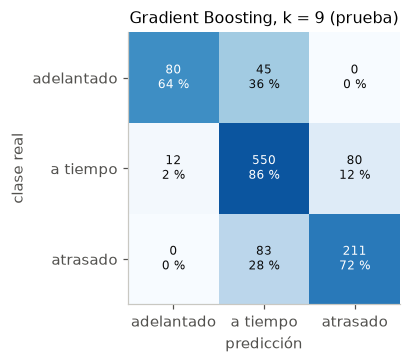

In [5]:
mejor_clf = hiper[hiper["k"] == 9].sort_values("F1_macro_val", ascending=False)["modelo"].iloc[0]
cm = matrices[(9, mejor_clf)]
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        frac = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]}\n{100 * frac:.0f} %", ha="center", va="center", fontsize=8,
                color="white" if frac > 0.55 else graficos.TEXTO)
ax.set(xticks=range(3), yticks=range(3), xticklabels=CLASES, yticklabels=CLASES,
       xlabel="predicción", ylabel="clase real", title=f"{mejor_clf}, k = 9 (prueba)")
ax.grid(False)
graficos.guardar(fig, DIR_FIG / "05_matriz_confusion_k9.png")
pd.DataFrame(cm, index=CLASES, columns=CLASES).to_csv(DIR_TAB / "05_matriz_confusion_k9.csv")

## 4. Sensibilidad a los umbrales: terciles del entrenamiento
Los umbrales fijos (5 y 3 min) se comparan con terciles del atraso final calculados solo con entrenamiento, usando el mismo clasificador y sus hiperparámetros de k = 9.

In [6]:
tr9, te9 = x9[x9["conjunto"] == "train"], x9[x9["conjunto"] == "test"]
q1, q2 = np.quantile(tr9["y"], [1 / 3, 2 / 3])
cols9 = columnas_modelo(x9)
params = json.loads(hiper[(hiper["k"] == 9) & (hiper["modelo"] == mejor_clf)]["mejores_parametros"].item())
sens = []
for nombre_u, (atraso, adelanto) in {"Fijos (≥ 5 / ≤ −3 min)": (UMBRAL_ATRASO, UMBRAL_ADELANTO),
                                    f"Terciles (> {q2:.0f} / < {q1:.0f} min)": (q2 + 1e-9, -q1 + 1e-9)}.items():
    y_tr, y_te = a_clase(tr9["y"], atraso, adelanto), a_clase(te9["y"], atraso, adelanto)
    m = pipeline(cols9, clone(CLASIFICADORES[mejor_clf][0]).set_params(**params)).fit(tr9[cols9], y_tr)
    prob = puntaje_atrasado(m, te9[cols9])
    sens.append({"umbrales": nombre_u, **{f"pct_{c}": 100 * np.mean(y_te == c) for c in CLASES},
                 **metricas_clasificacion(y_te, m.predict(te9[cols9]), prob)})
sens = pd.DataFrame(sens)
sens.to_csv(DIR_TAB / "05_sensibilidad_umbrales.csv", index=False, float_format="%.6f")
sens.round(3)

,umbrales,pct_adelantado,pct_a tiempo,pct_atrasado,exactitud,F1_atrasado,F1_macro,exactitud_bal,AUC_PR_atrasado
0,Fijos (≥ 5 / ≤ −3 min),11.781,60.509,27.710,0.793,0.721,0.764,0.738,0.804
1,Terciles (> 5 / < 0 min),24.694,52.875,22.432,0.707,0.726,0.680,0.673,0.809


## 5. Conclusiones
- P2 es el mismo problema que P1 expresado en tres estados: mismas observaciones, variables y partición; solo cambia que el objetivo se discretiza con los umbrales de 5 y 3 min.
- Las clases están desbalanceadas: en prueba 60,5 % a tiempo, 27,7 % atrasado y 11,8 % adelantado.
- Gradient Boosting es el mejor clasificador en validación (F1 macro 0,752) y en prueba en k = 9: exactitud 0,793, F1 macro 0,764, F1 de atrasado 0,721, exactitud balanceada 0,738 y AUC-PR 0,804. Random Forest y AdaBoost lo siguen; la persistencia de clase se queda en 0,615 de F1 macro.
- Discretizar el regresor de P1 da casi el mismo resultado (exactitud 0,796, F1 macro 0,762, AUC-PR 0,819): P2 no necesita un modelo propio y puede derivarse de P1.
- La exactitud supera 0,80 desde k = 15 (0,832); en k = 9 y 12 queda en 0,79–0,80.
- Con terciles (> 5 y < 0 min) la clase "adelantado" se vuelve ambigua y el F1 macro cae a 0,680; los umbrales fijos de 5 y 3 min separan mejor las clases.

In [7]:
import platform, sklearn
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.14.2 | pandas 3.0.3 | numpy 2.5.0 | scikit-learn 1.9.0
